# Projeto final: meta-aprendizado para o aprendizado ativo em fluxos com concept drift

Reproduzo Martins, Cano e Barbon Jr. (2023, *Pattern Recognition*), em que um meta-modelo escolhe o limiar de
incerteza do aprendizado ativo a cada drift, e acrescento três coisas: as comparações que faltam no artigo, um
meta-modelo que prevê o desempenho de cada limiar e as meta-características das Atividades 1 e 2.

In [1]:
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from scipy import stats
from sklearn.model_selection import GroupKFold

import atividade1 as a1
import fluxos as fx

pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_colwidth", 70)
plt.rcParams.update({
    "figure.facecolor": a1.SUPERFICIE, "axes.facecolor": a1.SUPERFICIE, "savefig.facecolor": a1.SUPERFICIE,
    "axes.edgecolor": a1.TINTA_2, "axes.labelcolor": a1.TINTA, "text.color": a1.TINTA,
    "xtick.color": a1.TINTA_2, "ytick.color": a1.TINTA_2, "grid.color": a1.GRADE, "grid.linewidth": 0.8,
    "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "figure.dpi": 110,
})
NOMES_FIXOS = [f"Z = {z:g}".replace(".", ",") for z in fx.FIXOS]

## 0. Fluxos

Os 34 fluxos do artigo, sem os 13 do CTU-13 (em que todos os limiares empatam) e sem o INSECTS fora de controle,
que não tem drift. Os sintéticos são gerados de novo com os tamanhos e ruídos do artigo, que não publica os arquivos.

In [2]:
tamanhos = {nome: fx.prepara(nome) for nome in fx.FLUXOS}


def origem(nome):
    if nome in ("electricity", "poker"):
        return "OpenML"
    return "USP DS Repository" if nome in fx.INSECTS else "gerado"


quadro_fluxos = pd.DataFrame([{"fluxo": n, "origem": origem(n), "exemplos": tamanhos[n],
                               "atributos": fx.carrega(n)[0].shape[1], "classes": int(fx.carrega(n)[1].max()) + 1}
                              for n in fx.FLUXOS]).set_index("fluxo")
ordem = sorted(fx.FLUXOS, key=lambda n: -tamanhos[n] * quadro_fluxos.loc[n, "atributos"])
print(f"Quadro 1: {len(quadro_fluxos)} fluxos de avaliação, {quadro_fluxos.exemplos.sum():,} exemplos".replace(",", "."))
quadro_fluxos

Quadro 1: 20 fluxos de avaliação. 8.083.231 exemplos


,origem,exemplos,atributos,classes
fluxo,,,,
electricity,OpenML,45312,7,2
rbf_250k,gerado,250000,50,2
rbf_500k,gerado,500000,10,2
rbf_1m,gerado,1000000,10,2
led_0,gerado,1000000,24,10
led_10,gerado,1000000,24,10
led_20,gerado,1000000,24,10
hyperplane,gerado,250000,10,2
poker,OpenML,829201,10,10


## 1. Reprodução do nível base

VFDT do scikit-multiflow 0.5.3, a biblioteca do artigo, num Python 3.8 à parte. O modelo pede o rótulo quando a
entropia da previsão passa do limiar Z. O Quadro 2 separa o que o artigo informa do que precisei inferir ou escolher.

In [3]:
quadro_parametros = pd.DataFrame([
    ("classificador", "VFDT padrão do scikit-multiflow", "artigo"),
    ("detector", "ADWIN com delta de 0,0001", "artigo"),
    ("incerteza", "entropia da previsão em base 2", "artigo"),
    ("limiar inicial", "0,5", "artigo"),
    ("margem do Algoritmo 1", "0,02", "artigo"),
    ("meta-modelo", "Random Forest padrão", "artigo"),
    ("meta-características", "18 do TSFEL por atributo, resumidas em média, mínimo, máximo e desvio; fs de 20% da janela", "artigo"),
    ("tamanho da meta-base", "2.026 janelas", "artigo"),
    ("treino inicial", "200 exemplos", "inferido: padrão do EvaluatePrequential e 0,45% de rótulos no electricity"),
    ("previsão vazia", "conta como incerta e pede o rótulo", "inferido: sem isso o modelo para de pedir rótulos"),
    ("limiares candidatos", "0,05, 0,1 e de 0,2 a 0,9", "escolhido: no artigo o limiar chega a 0,71"),
    ("fluxos da meta-base", "30 mil exemplos, gerador e parâmetros sorteados", "escolhido: o artigo usa cerca de 300 mil"),
    ("janelas", "64 exemplos ou mais; treino inicial de min(200, metade da janela)", "escolhido"),
    ("INSECTS", "normalizado entre 0 e 1, como o arquivo _norm original", "escolhido"),
    ("fluxos gerados", "mesmos tamanhos e ruídos do artigo, parâmetros restantes escolhidos", "escolhido"),
], columns=["item", "valor", "fonte"]).set_index("item")
print("Quadro 2: parâmetros do artigo e lacunas preenchidas")
quadro_parametros

Quadro 2: parâmetros do artigo e lacunas preenchidas


,valor,fonte
item,,
classificador,VFDT padrão do scikit-multiflow,artigo
detector,"ADWIN com delta de 0,0001",artigo
incerteza,entropia da previsão em base 2,artigo
limiar inicial,"0,5",artigo
margem do Algoritmo 1,"0,02",artigo
meta-modelo,Random Forest padrão,artigo
meta-características,"18 do TSFEL por atributo, resumidas em média, mínimo, máximo e des...",artigo
tamanho da meta-base,2.026 janelas,artigo
treino inicial,200 exemplos,"inferido: padrão do EvaluatePrequential e 0,45% de rótulos no elec..."


In [4]:
CONFIGS_BASE = [{"nome": nome, "chave": f"z{z:g}", "tipo": "fixo", "z": z} for nome, z in zip(NOMES_FIXOS, fx.FIXOS)]
CONFIGS_BASE.append({"nome": "todos os rótulos", "chave": "todos", "tipo": "todos"})


def implantar(configs, metas=None):
    tarefas = [(f"{n}__{c['chave']}", (n, c, (metas or {}).get(c["chave"]))) for n in ordem for c in configs]
    return pd.DataFrame(fx.roda("implantacao", tarefas, fx.implanta))


base = implantar(CONFIGS_BASE)
acc = base.pivot(index="fluxo", columns="config", values="acc").loc[fx.FLUXOS]
rot = base.pivot(index="fluxo", columns="config", values="rot").loc[fx.FLUXOS]
artigo_acc = pd.DataFrame({n: v[0] for n, v in fx.ARTIGO.items()}, index=NOMES_FIXOS + ["Z_MtL", "todos os rótulos"]).T
artigo_rot = pd.DataFrame({n: v[1] for n, v in fx.ARTIGO.items()}, index=NOMES_FIXOS + ["Z_MtL"]).T

quadro_todos = pd.DataFrame({"artigo": artigo_acc["todos os rótulos"], "reprodução": acc["todos os rótulos"]})
quadro_todos["diferença"] = quadro_todos["reprodução"] - quadro_todos["artigo"]
print(f"Quadro 3: acurácia com todos os rótulos; diferença absoluta mediana de {quadro_todos['diferença'].abs().median():.2f} p.p.")
quadro_todos.round(2)

Quadro 3: acurácia com todos os rótulos; diferença absoluta mediana de 0.03 p.p.


,artigo,reprodução,diferença
electricity,78.73,78.74,0.01
hyperplane,89.16,90.09,0.93
insects_abrupt_bal,53.78,53.83,0.05
insects_abrupt_imb,66.15,66.16,0.01
insects_gradual_bal,60.89,60.44,-0.45
insects_gradual_imb,57.67,57.65,-0.02
insects_incr_abrupt_bal,57.66,57.67,0.01
insects_incr_abrupt_imb,64.59,64.56,-0.03
insects_incremental_bal,52.22,52.21,-0.01
insects_incremental_imb,67.08,67.07,-0.01


In [5]:
grupo = quadro_fluxos.origem.map(lambda o: "gerado" if o == "gerado" else "real")
quadro_fixos = pd.DataFrame({
    "acurácia (p.p.)": (acc[NOMES_FIXOS] - artigo_acc[NOMES_FIXOS]).abs().mean(axis=1),
    "rótulos (p.p.)": (rot[NOMES_FIXOS] - artigo_rot[NOMES_FIXOS]).abs().mean(axis=1),
    "rótulos com Z = 0,5, artigo (%)": artigo_rot["Z = 0,5"], "rótulos com Z = 0,5 (%)": rot["Z = 0,5"],
    "origem": grupo})
resumo = quadro_fixos.groupby("origem")[["acurácia (p.p.)", "rótulos (p.p.)"]].mean()
TRAVADOS = list(rot.index[rot["Z = 0,5"] < 5])
print("Quadro 4: diferença absoluta média para o artigo nos 5 limiares fixos; médias por origem: "
      + "; ".join(f"{o} {r['acurácia (p.p.)']:.1f} e {r['rótulos (p.p.)']:.1f}" for o, r in resumo.iterrows()))
print(f"fluxos que param de pedir rótulos com Z = 0,5 (menos de 5%): {', '.join(TRAVADOS)}")
quadro_fixos.round(2)

Quadro 4: diferença absoluta média para o artigo nos 5 limiares fixos; médias por origem: gerado 19.9 e 40.8; real 3.1 e 7.6
fluxos que param de pedir rótulos com Z = 0,5 (menos de 5%): electricity, rbf_250k, rbf_500k, rbf_1m, led_0, hyperplane, poker


,acurácia (p.p.),rótulos (p.p.),"rótulos com Z = 0,5, artigo (%)","rótulos com Z = 0,5 (%)",origem
electricity,5.33,27.45,1.69,0.46,real
hyperplane,28.99,66.58,56.48,1.36,gerado
insects_abrupt_bal,0.48,3.04,27.36,25.08,real
insects_abrupt_imb,3.03,7.38,41.36,33.88,real
insects_gradual_bal,6.10,1.45,15.52,15.62,real
insects_gradual_imb,1.66,3.99,30.34,22.54,real
insects_incr_abrupt_bal,2.90,2.89,27.02,23.18,real
insects_incr_abrupt_imb,2.39,11.82,51.16,46.05,real
insects_incremental_bal,4.57,1.58,38.06,38.55,real
insects_incremental_imb,2.75,4.74,65.38,58.81,real


Em 7 fluxos o modelo para de pedir rótulos logo no começo. Depois que a árvore se divide, as folhas novas têm poucos
exemplos e o Naive Bayes delas dá probabilidade 1 a uma classe; a entropia fica em 0 e a folha não recebe mais
rótulos. O artigo mostra o mesmo no electricity com Z = 0,7 (0,45% dos rótulos), mas não nos fluxos gerados. Na
seção 5 repito as comparações sem esses fluxos.

In [6]:
X, y = fx.carrega("hyperplane")
_, _, marca = fx.ativo(np.asarray(X[:20_000]), np.asarray(y[:20_000]), 0.5, np.unique(y), mascara=True)
print("hyperplane com Z = 0,5, rótulos pedidos a cada 2.000 exemplos:", marca.reshape(-1, 2000).sum(axis=1))

hyperplane com Z = 0,5, rótulos pedidos a cada 2.000 exemplos: [1766 1639    0    0    0    0    0    0    0    0]


## 2. Meta-base

Algoritmo 2 do artigo. Cada fluxo sintético é cortado pelo ADWIN, e cada janela vira uma linha com a acurácia e os
rótulos dos 10 limiares candidatos e as meta-características. As das Atividades 1 e 2 usam a classe, então são
calculadas só com os exemplos que o modelo pediu com Z = 0,5. Paro em 2.026 janelas, como no artigo.

In [7]:
resultados = fx.roda("meta_base", [(f"f{i:03d}", (i,)) for i in range(150)], fx.janelas_meta)
meta_base = pd.DataFrame([l for r in resultados for l in r]).sort_values(["fluxo", "ini"]).head(2026).reset_index(drop=True)
meta_base.to_csv("meta_base.csv", index=False)
alvo = fx.alvo(meta_base)

quadro_meta = meta_base.assign(alvo=alvo).groupby("gerador").agg(
    fluxos=("fluxo", "nunique"), janelas=("n", "size"), tamanho_mediano=("n", "median"),
    alvo_medio=("alvo", "mean"), com_atividades=("a1_NumberOfInstances", lambda s: s.notna().mean()))
print(f"Quadro 5: meta-base com {len(meta_base)} janelas de {meta_base.fluxo.nunique()} fluxos; "
      f"tamanho de {meta_base.n.min()} a {meta_base.n.max():,} exemplos".replace(",", "."))
display(quadro_meta.round(3))
print("limiar ideal (alvo):", dict(zip(*np.unique(alvo, return_counts=True))))

Quadro 5: meta-base com 2026 janelas de 117 fluxos; tamanho de 64 a 28.744 exemplos


,fluxos,janelas,tamanho_mediano,alvo_medio,com_atividades
gerador,,,,,
hyper,20,203,1024.0,0.817,1.0
mixed,20,504,256.0,0.833,1.0
rbf,20,257,576.0,0.774,1.0
sine,19,463,416.0,0.754,1.0
stagger,19,322,400.0,0.636,1.0
tree,19,277,640.0,0.754,1.0


limiar ideal (alvo): {0.05: 99, 0.1: 15, 0.2: 34, 0.3: 42, 0.4: 67, 0.5: 63, 0.6: 93, 0.7: 123, 0.8: 199, 0.9: 1291}


## 3. Meta-modelos

O meta-modelo do artigo prevê o limiar ideal (regressão). O segundo prevê a acurácia e os rótulos de cada limiar
candidato e escolhe pela regra do artigo, como o regressor sobre P da Atividade 1. As referências que o artigo não
usa são prever sempre a média, o melhor limiar fixo da meta-base e o oráculo, que acerta o limiar de cada janela.

In [8]:
z_media = float(alvo.mean())
z_melhor_fixo = fx.CANDIDATOS[fx.melhor_z(meta_base[fx.ACC].mean().to_numpy(), meta_base[fx.ROT].mean().to_numpy())]
METODOS = [(m, c) for m in ("regressão", "desempenho") for c in fx.CONJUNTOS]
dobras = list(GroupKFold(10).split(meta_base, groups=meta_base.fluxo))


def previsao_cv(metodo, conjunto, treino, teste):
    m = fx.treina(meta_base.iloc[treino], metodo, conjunto)
    return teste, fx.recomenda(m, meta_base.iloc[teste])


z_cv = {}
saidas = Parallel(n_jobs=fx.N_JOBS)(delayed(previsao_cv)(m, c, tr, te) for m, c in METODOS for tr, te in dobras)
for k, (m, c) in enumerate(METODOS):
    z = np.zeros(len(meta_base))
    for teste, previsto in saidas[k * len(dobras):(k + 1) * len(dobras)]:
        z[teste] = previsto
    z_cv[(m, c)] = z
media_cv = np.zeros(len(meta_base))
for treino, teste in dobras:
    media_cv[teste] = alvo[treino].mean()

rmse = lambda z: float(np.sqrt(np.mean((np.asarray(z) - alvo) ** 2)))
quadro_rmse = pd.DataFrame({"RMSE": {"prever a média": rmse(media_cv), **{c: rmse(z_cv[("regressão", c)]) for c in fx.CONJUNTOS}}})
print(f"Quadro 6: RMSE do limiar na meta-base, validação cruzada por fluxo (artigo: 0.241); "
      f"média {z_media:.3f}, melhor fixo {z_melhor_fixo:g}")
quadro_rmse.round(3)

Quadro 6: RMSE do limiar na meta-base, validação cruzada por fluxo (artigo: 0.241); média 0.764, melhor fixo 0.9


,RMSE
Atividade 1,0.190
Atividade 2,0.178
Atividades 1 e 2,0.178
prever a média,0.241
temporais,0.234
todas,0.178


In [9]:
cortes = dict(zip(ordem, fx.roda("cortes", [(n, (n,)) for n in ordem], fx.cortes_avaliacao)))
tarefas = [(f"{n}__{a}", (n, a, b)) for n in ordem for a, b in cortes[n]]
janelas = pd.DataFrame(fx.roda("janelas", tarefas, fx.janela_avaliacao))
janelas.to_csv("janelas_avaliacao.csv", index=False)
alvo_j = fx.alvo(janelas)
quadro_janelas = janelas.assign(alvo=alvo_j).groupby("fluxo").agg(
    janelas=("n", "size"), tamanho_mediano=("n", "median"), alvo_medio=("alvo", "mean"),
    rotulos_medianos=("rotulados_0.5", "median")).reindex(fx.FLUXOS)
print(f"Quadro 7: {len(janelas)} janelas dos fluxos de avaliação; sem drift detectado: "
      f"{', '.join(quadro_janelas.index[quadro_janelas.janelas.isna()])}")
quadro_janelas.round(3)

Quadro 7: 703 janelas dos fluxos de avaliação; sem drift detectado: led_20


,janelas,tamanho_mediano,alvo_medio,rotulos_medianos
fluxo,,,,
electricity,16.0,1312.0,0.478,205.5
rbf_250k,12.0,14352.0,0.883,3449.5
rbf_500k,24.0,7588.0,0.817,3409.0
rbf_1m,38.0,11120.0,0.729,3589.5
led_0,8.0,960.0,0.050,200.0
led_10,4.0,19096.0,0.875,6740.0
led_20,NaN,NaN,NaN,NaN
hyperplane,1.0,8392.0,0.800,3405.0
poker,100.0,1280.0,0.631,244.5


In [10]:
metas = dict(zip(METODOS, Parallel(n_jobs=fx.N_JOBS)(delayed(fx.treina)(meta_base, m, c) for m, c in METODOS)))
z_rec = {k: fx.recomenda(v, janelas) for k, v in metas.items()}


def escolhas(z_por_metodo, base_janelas):
    n = len(base_janelas)
    saida = {"oráculo": np.array([fx.melhor_z(a, r) for a, r in zip(base_janelas[fx.ACC].to_numpy(), base_janelas[fx.ROT].to_numpy())])}
    for nome, z in zip(NOMES_FIXOS, fx.FIXOS):
        saida[nome] = fx.indice_candidato(np.full(n, z))
    saida["média"] = fx.indice_candidato(np.full(n, z_media))
    saida["melhor fixo"] = fx.indice_candidato(np.full(n, z_melhor_fixo))
    saida.update({k: fx.indice_candidato(z) for k, z in z_por_metodo.items()})
    return saida


def resume(indices, base_janelas, z_alvo):
    m = fx.metricas_janelas(base_janelas, indices)
    z = np.array(fx.CANDIDATOS)[indices]
    return {"posição": m["posição"].mean(), "perda de acurácia (p.p.)": m["perda de acurácia (p.p.)"].mean(),
            "rótulos (%)": m["rótulos (%)"].mean(), "dentro da margem (%)": 100 * m["dentro da margem"].mean(),
            "RMSE do limiar": float(np.sqrt(np.mean((z - z_alvo) ** 2)))}


PRINCIPAIS = {"regressão (artigo)": ("regressão", "temporais"), "desempenho": ("desempenho", "temporais")}
esc = escolhas({k: z_rec[v] for k, v in PRINCIPAIS.items()}, janelas)
esc_cv = escolhas({k: z_cv[v] for k, v in PRINCIPAIS.items()}, meta_base)
esc_cv["média"] = fx.indice_candidato(media_cv)
melhor_cv = np.zeros(len(meta_base), int)
for treino, teste in dobras:
    parte = meta_base.iloc[treino]
    melhor_cv[teste] = fx.melhor_z(parte[fx.ACC].mean().to_numpy(), parte[fx.ROT].mean().to_numpy())
esc_cv["melhor fixo"] = melhor_cv
quadro_meta_nivel = pd.DataFrame({k: resume(v, janelas, alvo_j) for k, v in esc.items()}).T
quadro_meta_nivel["posição na meta-base (CV)"] = pd.Series({k: fx.metricas_janelas(meta_base, v)["posição"].mean() for k, v in esc_cv.items()})
print("Quadro 8: escolha do limiar janela a janela nos fluxos de avaliação (posição 1 = escolha da regra do artigo)")
quadro_meta_nivel.round(3)

Quadro 8: escolha do limiar janela a janela nos fluxos de avaliação (posição 1 = escolha da regra do artigo)


,posição,perda de acurácia (p.p.),rótulos (%),dentro da margem (%),RMSE do limiar,posição na meta-base (CV)
oráculo,1.000,0.576,33.729,100.000,0.000,1.003
"Z = 0,05",7.006,2.662,50.174,65.718,0.686,7.107
"Z = 0,1",6.593,2.392,47.712,66.287,0.641,7.228
"Z = 0,2",6.368,2.707,44.104,64.865,0.554,6.838
"Z = 0,5",5.248,2.723,37.881,63.869,0.340,5.423
"Z = 0,7",4.654,2.478,34.085,63.727,0.297,4.260
média,4.300,2.541,32.219,66.287,0.323,3.656
melhor fixo,4.471,2.644,29.657,64.296,0.375,3.376
regressão (artigo),5.036,2.526,36.651,66.430,0.326,3.644
desempenho,4.455,2.629,30.075,64.438,0.370,3.385


Friedman: χ² = 62.1, p = 1.8e-10, 19 fluxos


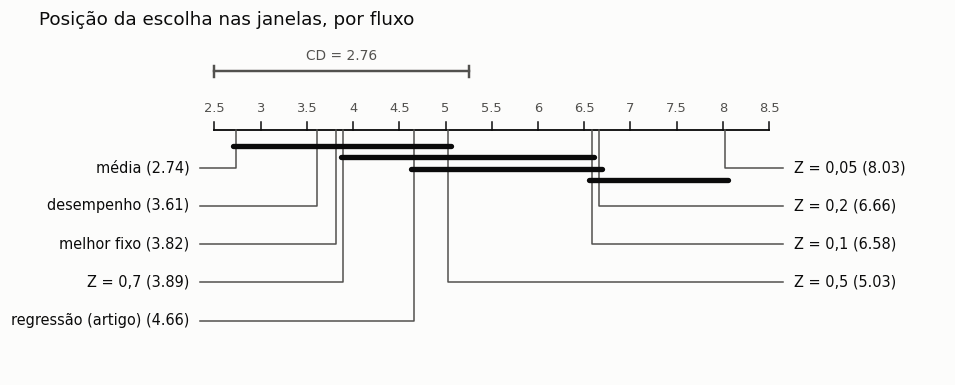

In [11]:
por_fluxo = pd.DataFrame({k: fx.metricas_janelas(janelas, v).groupby("fluxo")["posição"].mean()
                          for k, v in esc.items() if k != "oráculo"})
ranks = por_fluxo.rank(axis=1).mean()
cd = fx.diferenca_critica(len(ranks), len(por_fluxo))
f_meta = stats.friedmanchisquare(*[por_fluxo[c] for c in por_fluxo.columns])
print(f"Friedman: χ² = {f_meta.statistic:.1f}, p = {f_meta.pvalue:.2g}, {len(por_fluxo)} fluxos")
a1.diagrama_dc(ranks, cd, "Posição da escolha nas janelas, por fluxo")
plt.show()

## 4. Meta-características

Os dois meta-modelos com cinco conjuntos: as temporais do artigo, as da Atividade 1, as da Atividade 2, as das duas
atividades e todas juntas.

In [12]:
linhas = []
for (m, c), z in z_rec.items():
    r = resume(fx.indice_candidato(z), janelas, alvo_j)
    r["posição na meta-base (CV)"] = fx.metricas_janelas(meta_base, fx.indice_candidato(z_cv[(m, c)]))["posição"].mean()
    r["RMSE na meta-base (CV)"] = rmse(z_cv[(m, c)])
    linhas.append({"meta-modelo": m, "meta-características": c, "colunas": len(fx.CONJUNTOS[c]), **r})
quadro_conjuntos = pd.DataFrame(linhas).set_index(["meta-modelo", "meta-características"])
cobertura = janelas[fx.A1_COLS[0]].notna().mean()
print(f"Quadro 9: meta-modelos por conjunto de meta-características; as das Atividades 1 e 2 existem em "
      f"{100 * cobertura:.0f}% das janelas de avaliação e {100 * meta_base[fx.A1_COLS[0]].notna().mean():.0f}% das da meta-base")
quadro_conjuntos.round(3)

Quadro 9: meta-modelos por conjunto de meta-características; as das Atividades 1 e 2 existem em 99% das janelas de avaliação e 100% das da meta-base


colunas  posição  perda de acurácia (p.p.)  rótulos (%)  dentro da margem (%)  RMSE do limiar  posição na meta-base (CV)  RMSE na meta-base (CV)
meta-modelo meta-características                                                                                                                                                  
regressão   temporais                  72    5.036                     2.526       36.651                66.430           0.326                      3.644                   0.234
            Atividade 1                32    5.077                     2.561       36.549                65.292           0.332                      3.103                   0.190
            Atividade 2                32    4.552                     2.439       34.053                65.434           0.292                      3.165                   0.178
            Atividades 1 e 2           64    4.822                     2.452       36.109                67.710           0.329                      3.083                   0.178
            todas                     136    5.043                     2.463       36.644                66.145           0.331                      3.107                   0.178
desempenho  temporais                  72    4.455                     2.629       30.075                64.438           0.370                      3.385                   0.275
            Atividade 1                32    4.341                     2.576       32.149                66.572           0.336                      3.229                   0.260
            Atividade 2                32    4.455                     2.610       29.920                64.865           0.369                      3.285                   0.261
            Atividades 1 e 2           64    4.393                     2.590       30.155                65.149           0.368                      3.311                   0.264
            todas                     136    4.481                     2.707       29.726                64.723           0.373                      3.352                   0.272

In [13]:
pos_fluxo = {k: fx.metricas_janelas(janelas, fx.indice_candidato(z)).groupby("fluxo")["posição"].mean() for k, z in z_rec.items()}
pos_fluxo["média"] = por_fluxo["média"]
pos_fluxo["melhor fixo"] = por_fluxo["melhor fixo"]


def pareado(a, b):
    x, y = pos_fluxo[a], pos_fluxo[b]
    p = 1.0 if np.allclose(x, y) else float(stats.wilcoxon(x, y, zero_method="pratt").pvalue)
    return {"A": " ".join(a) if isinstance(a, tuple) else a, "B": " ".join(b) if isinstance(b, tuple) else b,
            "A melhor / pior / igual": f"{(x < y).sum()} / {(x > y).sum()} / {(x == y).sum()}",
            "Δ posição (A − B)": float((x - y).mean()), "p": p}


comparacoes = [(("desempenho", "temporais"), ("regressão", "temporais"))]
comparacoes += [((m, "temporais"), ref) for m in ("regressão", "desempenho") for ref in ("média", "melhor fixo")]
comparacoes += [((m, c), (m, "temporais")) for m in ("regressão", "desempenho") for c in ("Atividades 1 e 2", "todas")]
print("Quadro 10: comparações pareadas da posição média por fluxo (Wilcoxon; posição menor é melhor)")
pd.DataFrame([pareado(a, b) for a, b in comparacoes]).round(3)

Quadro 10: comparações pareadas da posição média por fluxo (Wilcoxon; posição menor é melhor)


,A,B,A melhor / pior / igual,Δ posição (A − B),p
0,desempenho temporais,regressão temporais,14 / 5 / 0,-0.657,0.060
1,regressão temporais,média,5 / 14 / 0,1.009,0.032
2,regressão temporais,melhor fixo,5 / 14 / 0,0.612,0.060
3,desempenho temporais,média,5 / 13 / 1,0.352,0.142
4,desempenho temporais,melhor fixo,7 / 4 / 8,-0.044,0.401
5,regressão Atividades 1 e 2,regressão temporais,12 / 6 / 1,-0.564,0.030
6,regressão todas,regressão temporais,10 / 8 / 1,-0.341,0.286
7,desempenho Atividades 1 e 2,desempenho temporais,8 / 9 / 2,0.003,0.825
8,desempenho todas,desempenho temporais,6 / 8 / 5,0.079,0.528


## 5. Nos fluxos

Algoritmo 3 do artigo: o limiar começa em 0,5 e muda a cada detecção do ADWIN, a partir das meta-características
da janela. Os meta-modelos são treinados na meta-base inteira; a média e o melhor fixo entram como limiares fixos.
Com as meta-características das atividades, se a janela tem menos de 30 rótulos ou uma classe só, o limiar não muda.

In [14]:
fmt = lambda z: f"{z:.2f}".replace(".", ",")
CONFIGS_META = [
    {"nome": f"média (Z = {fmt(z_media)})", "chave": "media", "tipo": "fixo", "z": z_media},
    {"nome": f"melhor fixo (Z = {fmt(z_melhor_fixo)})", "chave": "melhor_fixo", "tipo": "fixo", "z": z_melhor_fixo},
    {"nome": "regressão, temporais (artigo)", "chave": "reg_temporais", "tipo": "meta"},
    {"nome": "desempenho, temporais", "chave": "des_temporais", "tipo": "meta"},
    {"nome": "regressão, Atividades 1 e 2", "chave": "reg_atividades", "tipo": "meta"},
    {"nome": "desempenho, Atividades 1 e 2", "chave": "des_atividades", "tipo": "meta"},
]
metas_fluxo = {"reg_temporais": metas[("regressão", "temporais")], "des_temporais": metas[("desempenho", "temporais")],
               "reg_atividades": metas[("regressão", "Atividades 1 e 2")], "des_atividades": metas[("desempenho", "Atividades 1 e 2")]}
fluxo = pd.concat([base, implantar(CONFIGS_META, metas_fluxo)], ignore_index=True)
fluxo.to_csv("implantacao.csv", index=False)
acc = fluxo.pivot(index="fluxo", columns="config", values="acc").loc[fx.FLUXOS]
rot = fluxo.pivot(index="fluxo", columns="config", values="rot").loc[fx.FLUXOS]
ordem_cfg = NOMES_FIXOS + [c["nome"] for c in CONFIGS_META]
quadro_fluxo = pd.DataFrame({
    "acurácia (%)": acc[ordem_cfg].mean(), "rótulos (%)": rot[ordem_cfg].mean(),
    "rank da acurácia": (-acc[ordem_cfg]).rank(axis=1).mean(), "rank dos rótulos": rot[ordem_cfg].rank(axis=1).mean(),
    "limiar médio": fluxo.groupby("config").z_medio.mean().reindex(ordem_cfg)})
quadro_fluxo.loc["todos os rótulos", ["acurácia (%)", "rótulos (%)"]] = [acc["todos os rótulos"].mean(), 100.0]
sem_travar = [f for f in fx.FLUXOS if f not in TRAVADOS]
quadro_fluxo[f"acurácia nos {len(sem_travar)} (%)"] = acc.loc[sem_travar].mean()
quadro_fluxo[f"rótulos nos {len(sem_travar)} (%)"] = rot.loc[sem_travar].mean()
print(f"Quadro 11: médias nos {len(acc)} fluxos e nos {len(sem_travar)} em que o modelo não para de pedir rótulos "
      f"(rank entre as {len(ordem_cfg)} configurações, 1 = melhor)")
quadro_fluxo.round(2)

Quadro 11: médias nos 20 fluxos e nos 13 em que o modelo não para de pedir rótulos (rank entre as 11 configurações, 1 = melhor)


,acurácia (%),rótulos (%),rank da acurácia,rank dos rótulos,limiar médio,acurácia nos 13 (%),rótulos nos 13 (%)
config,,,,,,,
"Z = 0,05",62.02,38.53,4.20,9.80,0.05,61.81,57.73
"Z = 0,1",62.09,35.05,4.40,9.05,0.10,61.75,51.70
"Z = 0,2",61.35,32.52,4.70,8.15,0.20,61.10,47.90
"Z = 0,5",60.59,23.69,6.08,6.25,0.50,60.78,35.96
"Z = 0,7",60.17,21.59,5.68,4.97,0.70,59.72,32.83
"média (Z = 0,76)",59.34,17.10,7.02,3.92,0.76,58.25,25.39
"melhor fixo (Z = 0,90)",60.66,14.95,6.18,3.30,0.90,59.47,22.59
"regressão, temporais (artigo)",60.92,25.36,6.12,6.75,0.53,60.23,38.49
"desempenho, temporais",59.36,16.61,8.12,3.55,0.85,59.37,25.16


In [15]:
artigo = "regressão, temporais (artigo)"
quadro_zmtl = pd.DataFrame({
    "acurácia artigo": artigo_acc["Z_MtL"], "acurácia reprodução": acc[artigo],
    "rótulos artigo": artigo_rot["Z_MtL"], "rótulos reprodução": rot[artigo],
    "Z = 0,5 artigo (acurácia)": artigo_acc["Z = 0,5"], "Z = 0,5 reprodução (acurácia)": acc["Z = 0,5"],
    "trocas de limiar": fluxo[fluxo.config == artigo].set_index("fluxo").trocas})
dif = (quadro_zmtl["acurácia reprodução"] - quadro_zmtl["acurácia artigo"]).abs()
ganho_art = (artigo_acc["Z_MtL"] - artigo_acc["Z = 0,5"]).mean()
ganho_rep = (acc[artigo] - acc["Z = 0,5"]).mean()
print(f"Quadro 12: o meta-modelo do artigo, fluxo a fluxo; diferença absoluta mediana de {dif.median():.2f} p.p. na acurácia; "
      f"ganho médio sobre Z = 0,5 de {ganho_art:+.2f} p.p. no artigo e {ganho_rep:+.2f} p.p. aqui")
quadro_zmtl.round(2)

Quadro 12: o meta-modelo do artigo, fluxo a fluxo; diferença absoluta mediana de 4.21 p.p. na acurácia; ganho médio sobre Z = 0,5 de +0.73 p.p. no artigo e +0.33 p.p. aqui


,acurácia artigo,acurácia reprodução,rótulos artigo,rótulos reprodução,"Z = 0,5 artigo (acurácia)","Z = 0,5 reprodução (acurácia)",trocas de limiar
electricity,78.01,75.63,21.32,0.46,77.71,75.63,35
hyperplane,86.77,50.69,54.00,1.36,86.90,50.69,5
insects_abrupt_bal,58.05,57.33,25.29,25.42,57.53,58.35,31
insects_abrupt_imb,60.59,64.83,38.44,43.59,57.48,58.67,64
insects_gradual_bal,75.13,62.24,11.88,12.10,69.63,64.91,17
insects_gradual_imb,64.74,62.15,19.94,36.13,62.81,64.27,50
insects_incr_abrupt_bal,59.61,55.43,16.56,33.29,58.07,57.88,69
insects_incr_abrupt_imb,60.19,61.79,48.87,58.38,58.90,62.82,112
insects_incremental_bal,49.04,51.69,36.58,37.97,49.04,52.35,5
insects_incremental_imb,62.07,56.23,45.91,46.28,63.22,65.86,64


Acurácia: Friedman χ² = 8.3, p = 0.14


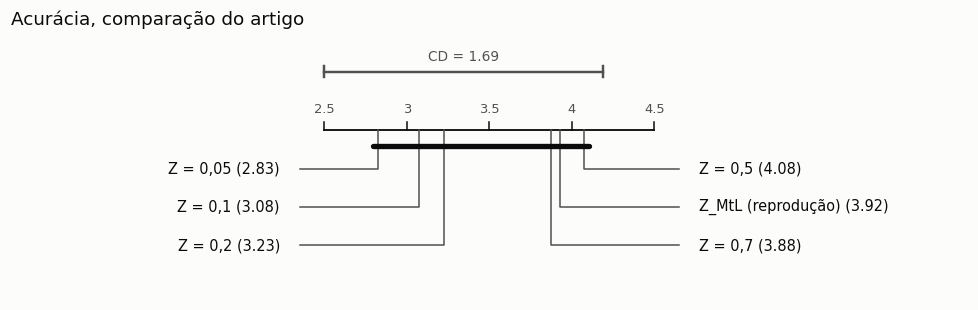

Rótulos pedidos: Friedman χ² = 53.1, p = 3.2e-10


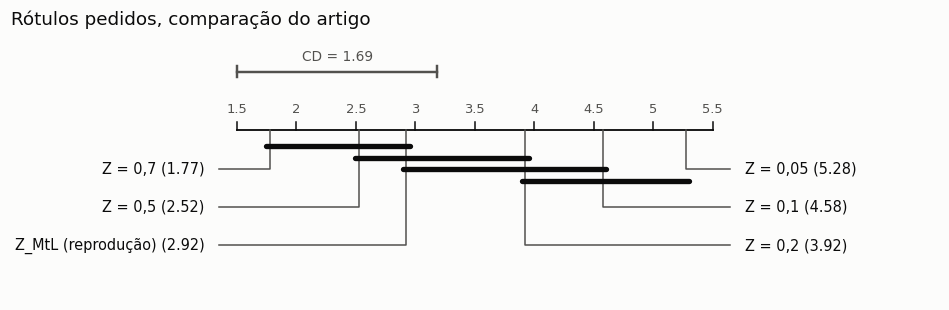

In [16]:
cols_artigo = NOMES_FIXOS + [artigo]
for tabela, rotulo, maior in ((acc, "Acurácia", True), (rot, "Rótulos pedidos", False)):
    t = tabela[cols_artigo].rename(columns={artigo: "Z_MtL (reprodução)"})
    r = (-t if maior else t).rank(axis=1).mean()
    fr = stats.friedmanchisquare(*[t[c] for c in t.columns])
    print(f"{rotulo}: Friedman χ² = {fr.statistic:.1f}, p = {fr.pvalue:.2g}")
    a1.diagrama_dc(r, fx.diferenca_critica(len(r), len(t)), f"{rotulo}, comparação do artigo")
    plt.show()

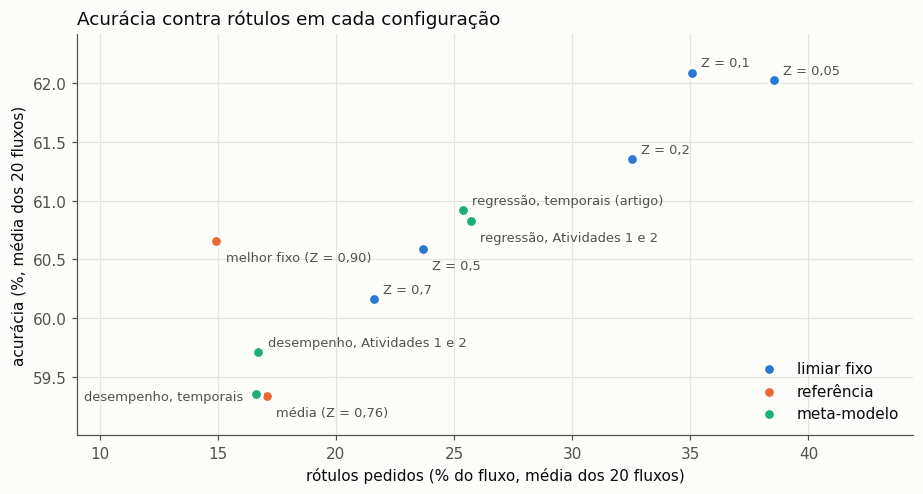

In [17]:
grupos = {"limiar fixo": NOMES_FIXOS, "referência": [c["nome"] for c in CONFIGS_META[:2]],
          "meta-modelo": [c["nome"] for c in CONFIGS_META[2:]]}
abaixo = ["Z = 0,5", "regressão, Atividades 1 e 2", CONFIGS_META[0]["nome"], CONFIGS_META[1]["nome"]]
deslocamento = {**{nome: (6, -13) for nome in abaixo}, "desempenho, temporais": (-8, -4)}
figura, eixo = plt.subplots(figsize=(8.5, 4.6))
for (rotulo, nomes), cor in zip(grupos.items(), a1.SERIES):
    x, y = quadro_fluxo.loc[nomes, "rótulos (%)"], quadro_fluxo.loc[nomes, "acurácia (%)"]
    eixo.scatter(x, y, s=60, color=cor, edgecolor=a1.SUPERFICIE, linewidth=2, label=rotulo, zorder=3)
    for nome, xi, yi in zip(nomes, x, y):
        dx, dy = deslocamento.get(nome, (6, 4))
        eixo.annotate(nome, (xi, yi), xytext=(dx, dy), textcoords="offset points", fontsize=8.5, color=a1.TINTA_2,
                      ha="right" if dx < 0 else "left")
eixo.margins(x=0.25, y=0.12)
eixo.set_xlabel("rótulos pedidos (% do fluxo, média dos 20 fluxos)")
eixo.set_ylabel("acurácia (%, média dos 20 fluxos)")
eixo.set_title("Acurácia contra rótulos em cada configuração", loc="left")
eixo.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

In [18]:
def pareado_fluxo(a, b, fluxos):
    linha = {"A": a, "B": b}
    for tabela, rotulo in ((acc, "acurácia"), (rot, "rótulos")):
        x, y = tabela.loc[fluxos, a], tabela.loc[fluxos, b]
        linha[f"Δ {rotulo} (A − B)"] = float((x - y).mean())
        linha[f"p {rotulo}"] = 1.0 if np.allclose(x, y) else float(stats.wilcoxon(x, y, zero_method="pratt").pvalue)
    return linha


nomes_meta = [c["nome"] for c in CONFIGS_META]
pares = [(nomes_meta[3], nomes_meta[2]), (nomes_meta[2], "Z = 0,5"), (nomes_meta[3], "Z = 0,5")]
pares += [(m, ref) for m in nomes_meta[2:4] for ref in nomes_meta[:2]]
pares += [(nomes_meta[4], nomes_meta[2]), (nomes_meta[5], nomes_meta[3])]
conjuntos_fluxos = {f"{len(acc)} fluxos": fx.FLUXOS, f"{len(sem_travar)} fluxos": sem_travar}
quadro_pares = pd.concat({g: pd.DataFrame([pareado_fluxo(a, b, f) for a, b in pares]) for g, f in conjuntos_fluxos.items()})
print(f"Quadro 13: comparações pareadas nos fluxos (Wilcoxon), com todos e sem os {len(TRAVADOS)} que param de pedir rótulos")
quadro_pares.round(3)

Quadro 13: comparações pareadas nos fluxos (Wilcoxon), com todos e sem os 7 que param de pedir rótulos


A                              B  Δ acurácia (A − B)  p acurácia  Δ rótulos (A − B)  p rótulos
20 fluxos 0          desempenho, temporais  regressão, temporais (artigo)              -1.558       0.032             -8.750      0.001
          1  regressão, temporais (artigo)                        Z = 0,5               0.331       0.910              1.669      0.091
          2          desempenho, temporais                        Z = 0,5              -1.227       0.030             -7.081      0.001
          3  regressão, temporais (artigo)               média (Z = 0,76)               1.581       0.466              8.266      0.001
          4  regressão, temporais (artigo)         melhor fixo (Z = 0,90)               0.257       0.866             10.413      0.000
          5          desempenho, temporais               média (Z = 0,76)               0.023       0.444             -0.484      0.239
          6          desempenho, temporais         melhor fixo (Z = 0,90)              -1.300       0.140              1.663      0.246
          7    regressão, Atividades 1 e 2  regressão, temporais (artigo)              -0.091       1.000              0.347      0.707
          8   desempenho, Atividades 1 e 2          desempenho, temporais               0.355       0.969              0.109      0.296
13 fluxos 0          desempenho, temporais  regressão, temporais (artigo)              -0.863       0.146            -13.331      0.000
          1  regressão, temporais (artigo)                        Z = 0,5              -0.543       0.542              2.534      0.216
          2          desempenho, temporais                        Z = 0,5              -1.406       0.146            -10.796      0.001
          3  regressão, temporais (artigo)               média (Z = 0,76)               1.983       0.273             13.099      0.000
          4  regressão, temporais (artigo)         melhor fixo (Z = 0,90)               0.768       0.685             15.909      0.000
          5          desempenho, temporais               média (Z = 0,76)               1.120       0.588             -0.232      0.497
          6          desempenho, temporais         melhor fixo (Z = 0,90)              -0.095       0.893              2.578      0.191
          7    regressão, Atividades 1 e 2  regressão, temporais (artigo)               0.230       0.635              0.485      0.787
          8   desempenho, Atividades 1 e 2          desempenho, temporais              -0.709       0.674             -0.042      0.483

In [19]:
custo = fluxo.groupby("config")[["segundos", "segundos_mf"]].sum().div(3600).reindex(["todos os rótulos"] + ordem_cfg)
custo.columns = ["horas de CPU", "horas nas meta-características"]
print(f"Quadro 14: custo da etapa nos fluxos, {custo['horas de CPU'].sum():.1f} h de CPU no total")
custo.round(2)

Quadro 14: custo da etapa nos fluxos, 22.4 h de CPU no total


,horas de CPU,horas nas meta-características
config,,
todos os rótulos,2.51,0.00
"Z = 0,05",2.14,0.00
"Z = 0,1",2.11,0.00
"Z = 0,2",2.06,0.00
"Z = 0,5",1.88,0.00
"Z = 0,7",1.95,0.00
"média (Z = 0,76)",1.40,0.00
"melhor fixo (Z = 0,90)",1.37,0.00
"regressão, temporais (artigo)",1.64,0.02
